# Week 2: Exploratory Financial Data Analysis
**CS Vision Data Analytics Internship – Set A | Financial & Operational Performance Analytics System**

**Dataset:** Global Superstore (clean version from Week 1): 51,290 order lines, 2011–2014.

**Objective:** Analyse revenue, expenses, profit, products, regions and monthly trends; summarise the data statistically; and produce a set of 15 visualisations with business interpretation.

## 1. Setup and Load the Clean Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10})

root = Path(r"C:\Users\tanis\OneDrive\Desktop\cs-vision-internship")
if not root.exists():                      # fallback: notebook is inside <project>/notebook
    root = Path.cwd().parent

df = pd.read_csv(root / "data" / "clean" / "clean_financial_data.csv",
                 parse_dates=["Order_Date", "Ship_Date"])

VIS = root / "visualizations"              # all charts are saved here as PNG files
VIS.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(VIS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

money_k = FuncFormatter(lambda x, _: f"{x/1000:,.0f}K")
money_m = FuncFormatter(lambda x, _: f"{x/1e6:,.1f}M")
GOOD, BAD, BLUE = "#2a9d8f", "#e63946", "#264653"

print("Loaded:", df.shape)
print("Project folder:", root)

Loaded: (51290, 40)
Project folder: C:\Users\tanis\OneDrive\Desktop\cs-vision-internship


## 2. Dataset Overview and Descriptive Statistics

In [2]:
print("Date range:", df.Order_Date.min().date(), "to", df.Order_Date.max().date())
print("Orders:", df.Order_ID.nunique(), "| Customers:", df.Customer_ID.nunique(),
      "| Products:", df.Product_ID.nunique(), "| Countries:", df.Country.nunique())
df[["Sales", "Quantity", "Discount", "Profit", "Shipping_Cost", "Cost", "Net_Profit", "Shipping_Days"]].describe().round(2)

Date range: 2011-01-01 to 2014-12-31
Orders: 25035 | Customers: 1590 | Products: 10292 | Countries: 147


,Sales,Quantity,Discount,Profit,Shipping_Cost,Cost,Net_Profit,Shipping_Days
count,51290.00,51290.00,51290.00,51290.00,51290.00,51290.00,51290.00,51290.00
mean,246.49,3.48,0.14,28.61,26.38,217.88,2.24,3.97
std,487.57,2.28,0.21,174.34,57.30,430.90,163.08,1.73
min,0.44,1.00,0.00,-6599.98,0.00,0.55,-7051.61,0.00
25%,30.76,2.00,0.00,0.00,2.61,26.88,-10.39,3.00
50%,85.05,3.00,0.00,9.24,7.79,73.64,2.66,4.00
75%,251.05,5.00,0.20,36.81,24.45,222.96,18.57,5.00
max,22638.48,14.00,0.85,8399.98,933.57,24449.56,8050.91,7.00


In [3]:
# Headline KPIs
kpi = pd.Series({
    "Total Sales":        df.Sales.sum(),
    "Total Cost":         df.Cost.sum(),
    "Gross Profit":       df.Gross_Profit.sum(),
    "Shipping Expense":   df.Operating_Expense.sum(),
    "Net Profit":         df.Net_Profit.sum(),
    "Gross Margin %":     df.Gross_Profit.sum() / df.Sales.sum() * 100,
    "Net Margin %":       df.Net_Profit.sum() / df.Sales.sum() * 100,
    "Avg Order Line Sales": df.Sales.mean(),
    "Loss-making Lines %": (df.Net_Profit < 0).mean() * 100,
})
kpi.round(2).to_frame("Value")

,Value
Total Sales,12642501.91
Total Cost,11175044.62
Gross Profit,1467457.29
Shipping Expense,1352820.69
Net Profit,114636.60
Gross Margin %,11.61
Net Margin %,0.91
Avg Order Line Sales,246.49
Loss-making Lines %,41.24


In [4]:
# Categorical distributions
for c in ["Category", "Segment", "Market", "Ship_Mode", "Order_Priority"]:
    print(df[c].value_counts().to_string(), "\n")

Category
Office Supplies    31273
Technology         10141
Furniture           9876 

Segment
Consumer       26518
Corporate      15429
Home Office     9343 

Market
APAC      11002
LATAM     10294
EU        10000
US         9994
EMEA       5029
Africa     4587
Canada      384 

Ship_Mode
Standard Class    30775
Second Class      10309
First Class        7505
Same Day           2701 

Order_Priority
Medium      29433
High        15501
Critical     3932
Low          2424 



## 3. Time-Series Analysis

### Chart 1 – Monthly Sales Trend

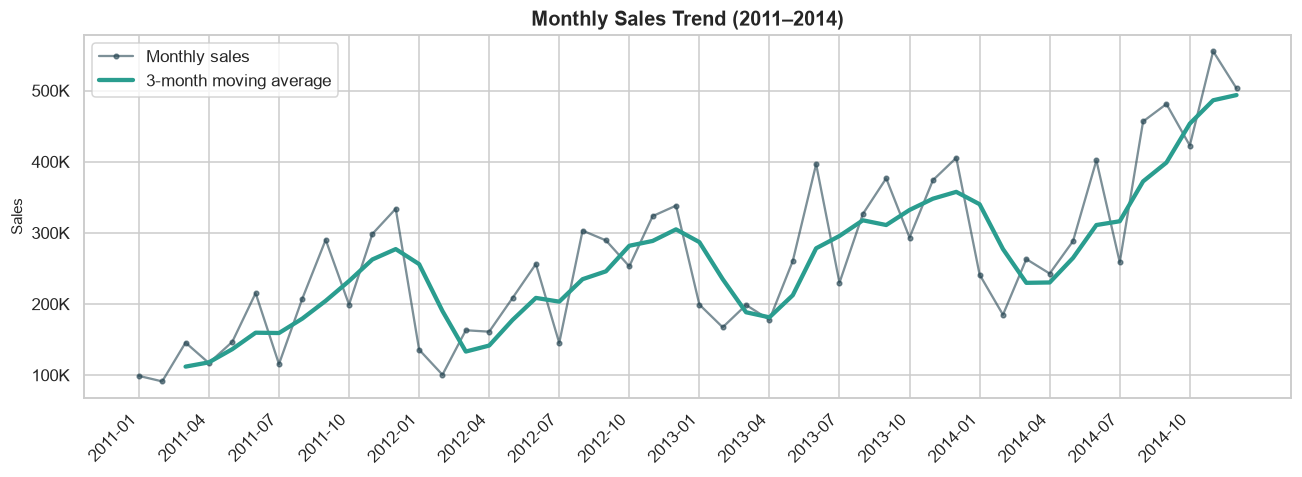

In [5]:
monthly = df.groupby("Year_Month")[["Sales", "Net_Profit"]].sum()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly.Sales, marker="o", ms=3, color=BLUE, alpha=.6, label="Monthly sales")
ax.plot(monthly.index, monthly.Sales.rolling(3).mean(), lw=2.8, color=GOOD, label="3-month moving average")
ax.set_xticks(range(0, len(monthly), 3)); ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right")
ax.yaxis.set_major_formatter(money_k)
ax.set(title="Monthly Sales Trend (2011–2014)", xlabel="", ylabel="Sales"); ax.legend()
save("01_monthly_sales_trend")

### Chart 2 – Monthly Net Profit

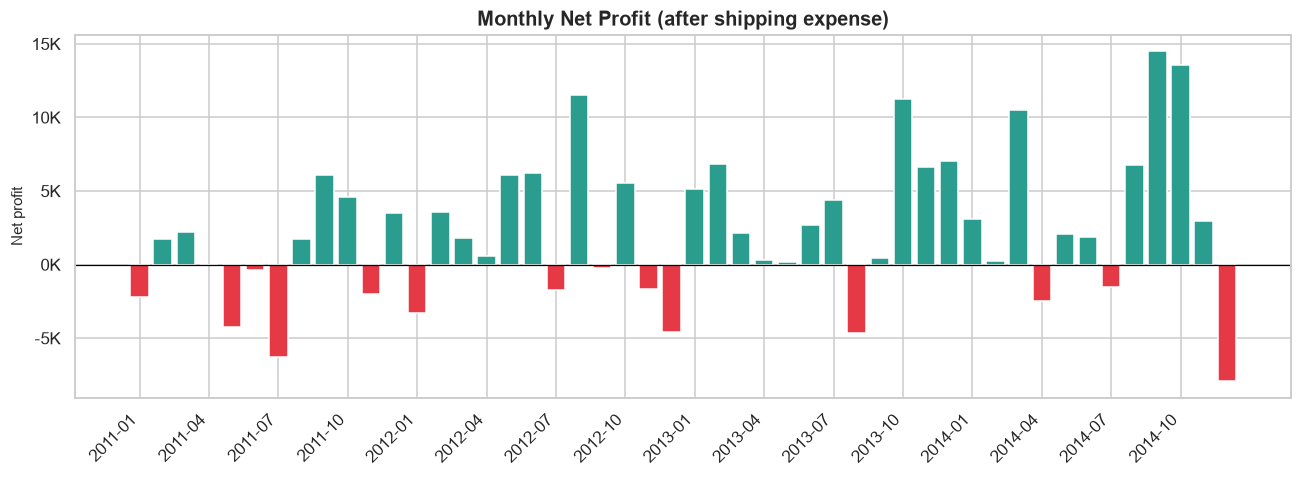

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(monthly.index, monthly.Net_Profit, color=[GOOD if v >= 0 else BAD for v in monthly.Net_Profit])
ax.axhline(0, color="black", lw=.8)
ax.set_xticks(range(0, len(monthly), 3)); ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right")
ax.yaxis.set_major_formatter(money_k)
ax.set(title="Monthly Net Profit (after shipping expense)", xlabel="", ylabel="Net profit")
save("02_monthly_net_profit")

### Chart 3 – Yearly Sales, Gross Profit and Net Profit

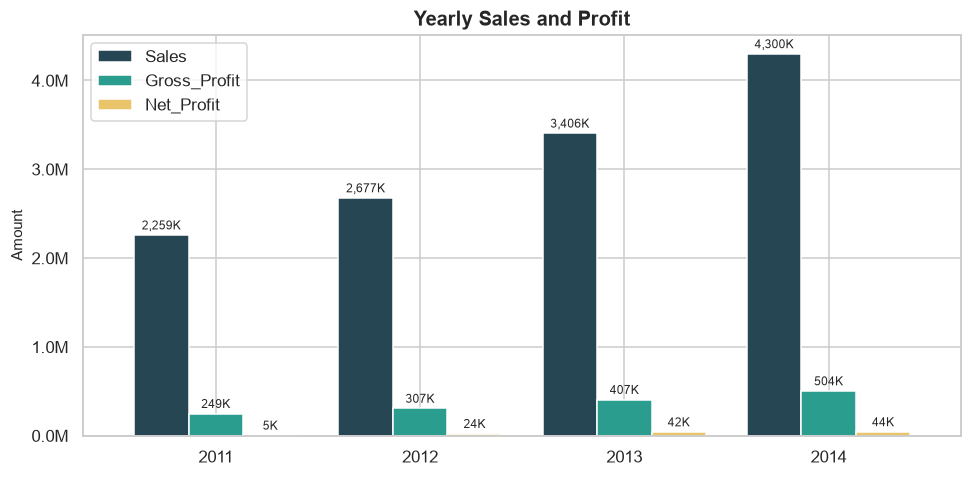

Year
2012    18.5
2013    27.2
2014    26.3


In [7]:
yearly = df.groupby("Year")[["Sales", "Gross_Profit", "Net_Profit"]].sum()
ax = yearly.plot.bar(figsize=(9, 4.5), color=[BLUE, GOOD, "#e9c46a"], rot=0, width=.8)
for c in ax.containers: ax.bar_label(c, labels=[f"{v/1000:,.0f}K" for v in c.datavalues], fontsize=8, padding=2)
ax.yaxis.set_major_formatter(money_m)
ax.set(title="Yearly Sales and Profit", xlabel="", ylabel="Amount")
save("03_yearly_sales_profit")
print((yearly.Sales.pct_change() * 100).round(1).dropna().rename("Sales growth % vs previous year").to_string())

### Chart 4 – Seasonality: Average Sales by Calendar Month

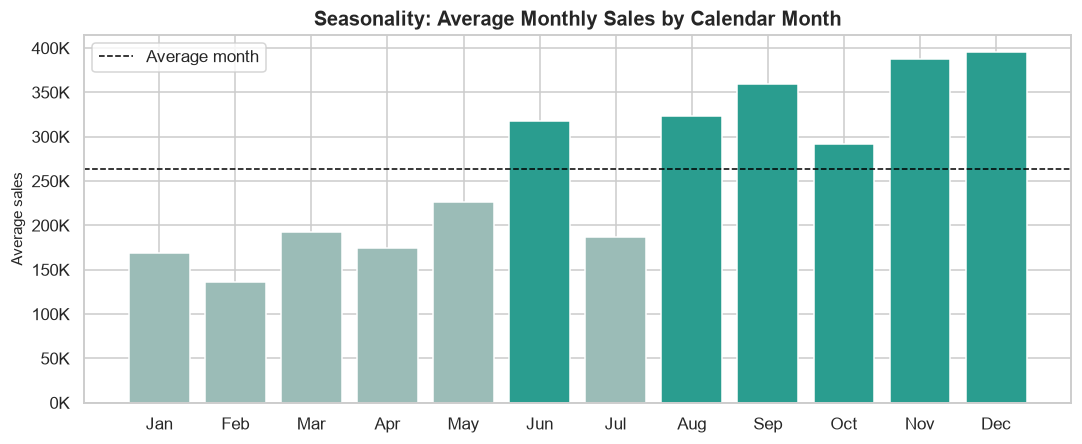

In [8]:
season = df.groupby(["Year", "Month"]).Sales.sum().groupby("Month").mean()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(season.index, season.values, color=[GOOD if v >= season.mean() else "#9bbcb7" for v in season.values])
ax.axhline(season.mean(), color="black", ls="--", lw=1, label="Average month")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(money_k); ax.legend()
ax.set(title="Seasonality: Average Monthly Sales by Calendar Month", xlabel="", ylabel="Average sales")
save("04_seasonality")

## 4. Product and Category Performance

### Chart 5 – Sales by Category

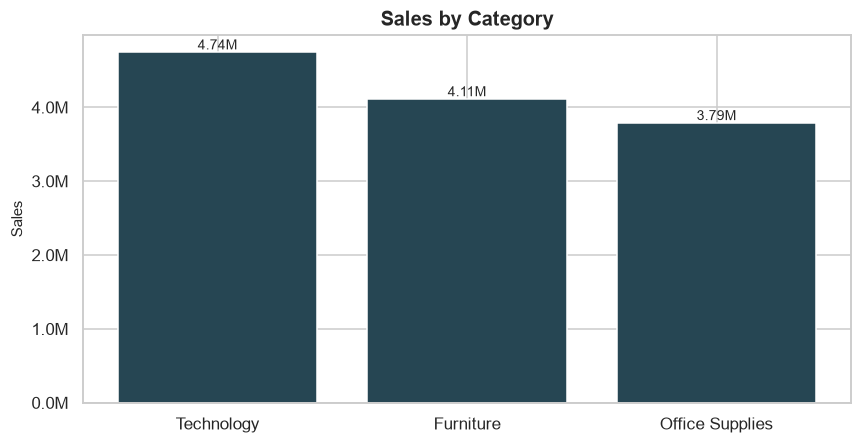

In [9]:
cat = df.groupby("Category").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum")).sort_values("Sales", ascending=False)
cat["Net_Margin_%"] = cat.Net_Profit / cat.Sales * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(cat.index, cat.Sales, color=BLUE)
for i, v in enumerate(cat.Sales): ax.text(i, v, f"{v/1e6:,.2f}M", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(money_m); ax.set(title="Sales by Category", xlabel="", ylabel="Sales")
save("05_sales_by_category")

### Chart 6 – Net Profit and Net Margin by Category

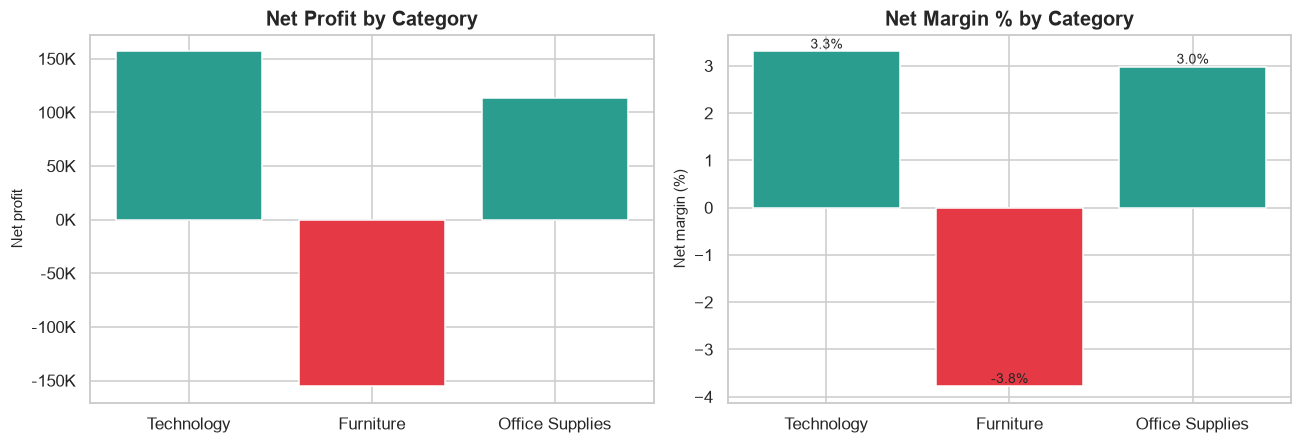

,Sales,Net_Profit,Net_Margin_%
Category,,,
Technology,4744557.50,156729.99,3.30
Furniture,4110874.19,-155115.94,-3.77
Office Supplies,3787070.23,113022.54,2.98


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(cat.index, cat.Net_Profit, color=[GOOD if v >= 0 else BAD for v in cat.Net_Profit])
ax[0].yaxis.set_major_formatter(money_k); ax[0].set(title="Net Profit by Category", xlabel="", ylabel="Net profit")
ax[1].bar(cat.index, cat["Net_Margin_%"], color=[GOOD if v >= 0 else BAD for v in cat["Net_Margin_%"]])
for i, v in enumerate(cat["Net_Margin_%"]): ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
ax[1].set(title="Net Margin % by Category", xlabel="", ylabel="Net margin (%)")
save("06_category_profit_margin")
cat.round(2)

### Chart 7 – Net Profit by Sub-Category

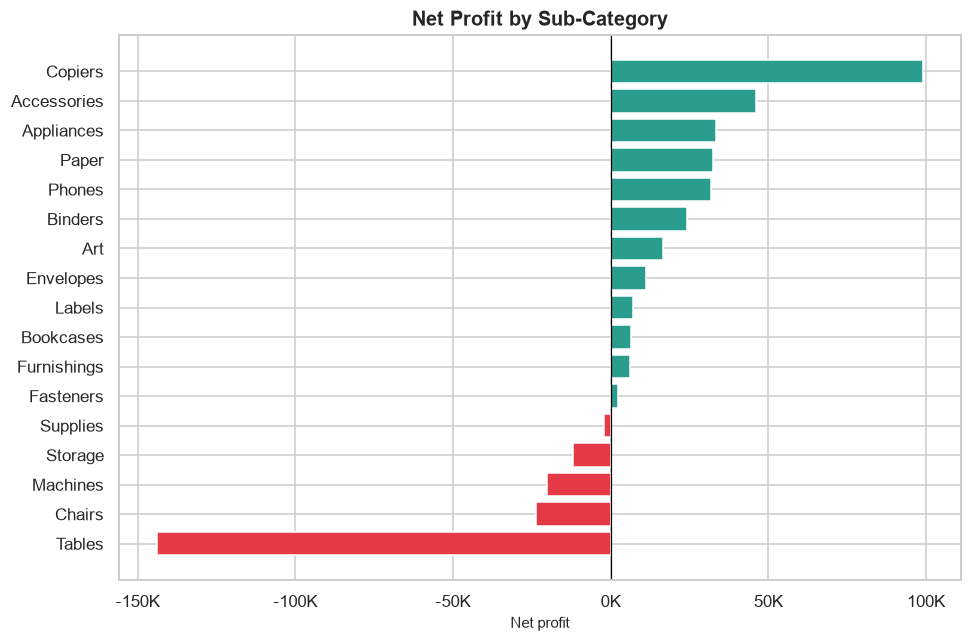

In [11]:
sub = df.groupby("Sub_Category").Net_Profit.sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub.values, color=[GOOD if v >= 0 else BAD for v in sub.values])
ax.axvline(0, color="black", lw=.8); ax.xaxis.set_major_formatter(money_k)
ax.set(title="Net Profit by Sub-Category", xlabel="Net profit", ylabel="")
save("07_subcategory_net_profit")

In [12]:
# Top and bottom products by net profit
prod = df.groupby("Product_Name").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum"), Units=("Quantity", "sum"))
print("TOP 10 PRODUCTS BY NET PROFIT"); print(prod.sort_values("Net_Profit", ascending=False).head(10).round(0).to_string())
print("\nBOTTOM 10 PRODUCTS BY NET PROFIT"); print(prod.sort_values("Net_Profit").head(10).round(0).to_string())

TOP 10 PRODUCTS BY NET PROFIT
                                         Sales  Net_Profit  Units
Product_Name                                                     
Canon imageCLASS 2200 Advanced Copier  61600.0     23924.0     20
Cisco Smart Phone, Full Size           76442.0     10173.0    139
Hoover Stove, Red                      31664.0      8319.0     62
Motorola Smart Phone, Full Size        73156.0      8210.0    134
Sauder Classic Bookcase, Traditional   39108.0      6568.0    113
Belkin Router, USB                     23470.0      6439.0    110
Hewlett Wireless Fax, High-Speed       23811.0      6153.0     75
Canon Wireless Fax, Laser              21929.0      5702.0     66
Cisco Smart Phone, with Caller ID      43128.0      5353.0     85
Memorex Router, Erganomic              21889.0      4850.0    111

BOTTOM 10 PRODUCTS BY NET PROFIT
                                             Sales  Net_Profit  Units
Product_Name                                                         
Cubi

## 5. Regional and Customer Segment Performance

### Chart 8 – Sales vs Net Profit by Region

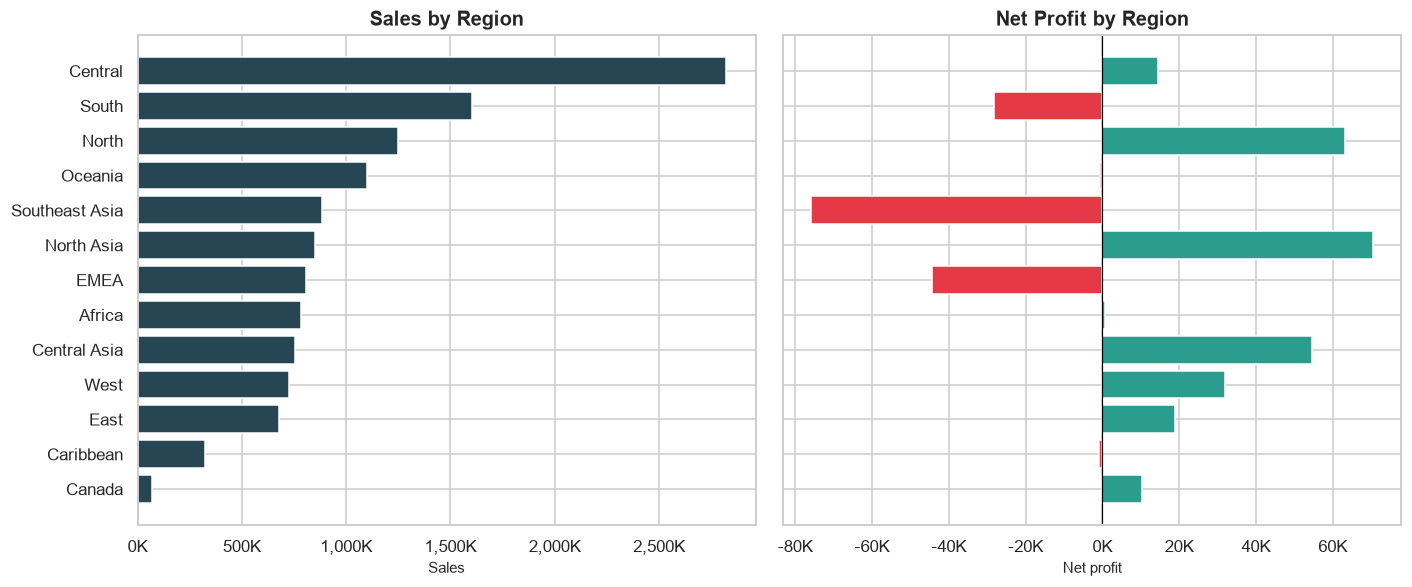

In [13]:
reg = df.groupby("Region").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum")).sort_values("Sales")
reg["Net_Margin_%"] = reg.Net_Profit / reg.Sales * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
ax[0].barh(reg.index, reg.Sales, color=BLUE); ax[0].xaxis.set_major_formatter(money_k); ax[0].set(title="Sales by Region", xlabel="Sales", ylabel="")
ax[1].barh(reg.index, reg.Net_Profit, color=[GOOD if v >= 0 else BAD for v in reg.Net_Profit])
ax[1].axvline(0, color="black", lw=.8); ax[1].xaxis.set_major_formatter(money_k); ax[1].set(title="Net Profit by Region", xlabel="Net profit")
save("08_region_sales_vs_profit")

### Chart 9 – Net Margin by Region

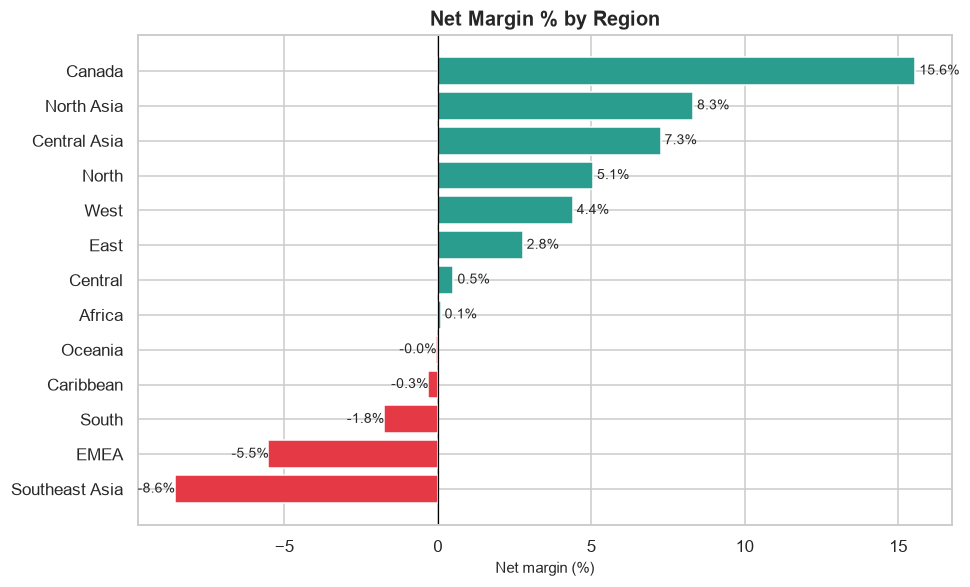

In [14]:
rm = reg["Net_Margin_%"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(rm.index, rm.values, color=[GOOD if v >= 0 else BAD for v in rm.values])
for i, v in enumerate(rm.values): ax.text(v, i, f" {v:.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=.8); ax.set(title="Net Margin % by Region", xlabel="Net margin (%)", ylabel="")
save("09_region_net_margin")

### Chart 10 – Customer Segment Performance

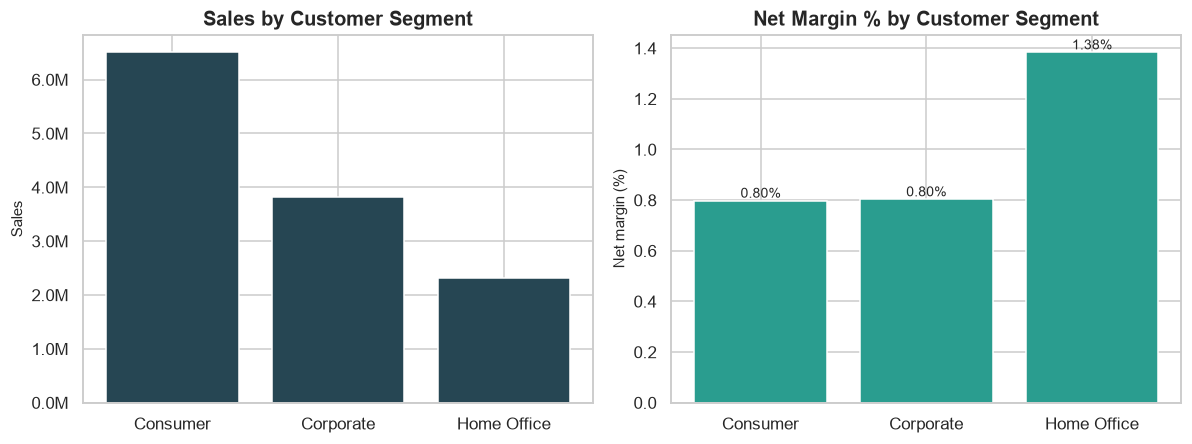

In [15]:
seg = df.groupby("Segment").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum"))
seg["Net_Margin_%"] = seg.Net_Profit / seg.Sales * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].bar(seg.index, seg.Sales, color=BLUE); ax[0].yaxis.set_major_formatter(money_m); ax[0].set(title="Sales by Customer Segment", xlabel="", ylabel="Sales")
ax[1].bar(seg.index, seg["Net_Margin_%"], color=GOOD)
for i, v in enumerate(seg["Net_Margin_%"]): ax[1].text(i, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
ax[1].set(title="Net Margin % by Customer Segment", xlabel="", ylabel="Net margin (%)")
save("10_segment_performance")

## 6. Discounts and Operational Costs

### Chart 11 – Discount Level vs Average Net Profit

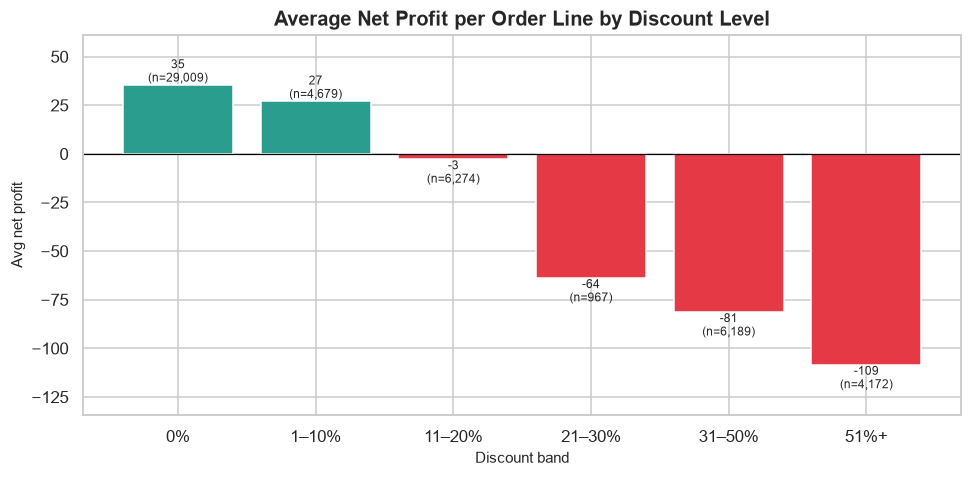

In [16]:
bands = pd.cut(df.Discount, [-0.001, 0, 0.1, 0.2, 0.3, 0.5, 1.0],
               labels=["0%", "1–10%", "11–20%", "21–30%", "31–50%", "51%+"])
disc = df.groupby(bands, observed=True).agg(Avg_Net_Profit=("Net_Profit", "mean"), Lines=("Net_Profit", "size"))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(disc.index.astype(str), disc.Avg_Net_Profit, color=[GOOD if v >= 0 else BAD for v in disc.Avg_Net_Profit])
for i, (v, n) in enumerate(zip(disc.Avg_Net_Profit, disc.Lines)):
    ax.text(i, v, f"{v:,.0f}\n(n={n:,})", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.axhline(0, color="black", lw=.8); ax.margins(y=.18)
ax.set(title="Average Net Profit per Order Line by Discount Level", xlabel="Discount band", ylabel="Avg net profit")
save("11_discount_vs_profit")

### Chart 12 – Shipping Cost as % of Sales by Ship Mode

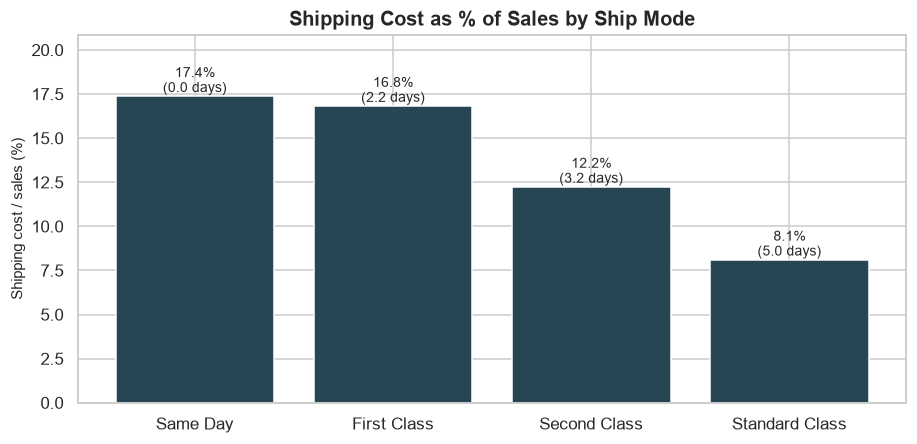

,Sales,Ship,Days,Ship_%_of_Sales
Ship_Mode,,,,
Same Day,667201.98,115974.06,0.04,17.38
First Class,1830976.14,308103.25,2.18,16.83
Second Class,2565671.68,314112.62,3.23,12.24
Standard Class,7578652.11,614630.76,5.00,8.11


In [17]:
ship = df.groupby("Ship_Mode").agg(Sales=("Sales", "sum"), Ship=("Shipping_Cost", "sum"), Days=("Shipping_Days", "mean"))
ship["Ship_%_of_Sales"] = ship.Ship / ship.Sales * 100
ship = ship.sort_values("Ship_%_of_Sales", ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(ship.index, ship["Ship_%_of_Sales"], color=BLUE)
for i, (v, d) in enumerate(zip(ship["Ship_%_of_Sales"], ship.Days)): ax.text(i, v, f"{v:.1f}%\n({d:.1f} days)", ha="center", va="bottom", fontsize=9)
ax.set(title="Shipping Cost as % of Sales by Ship Mode", xlabel="", ylabel="Shipping cost / sales (%)")
ax.set_ylim(0, ship["Ship_%_of_Sales"].max() * 1.2)
save("12_shipping_cost_by_mode")
ship.round(2)

## 7. Distributions

### Chart 13 – Distribution of Order-Line Sales

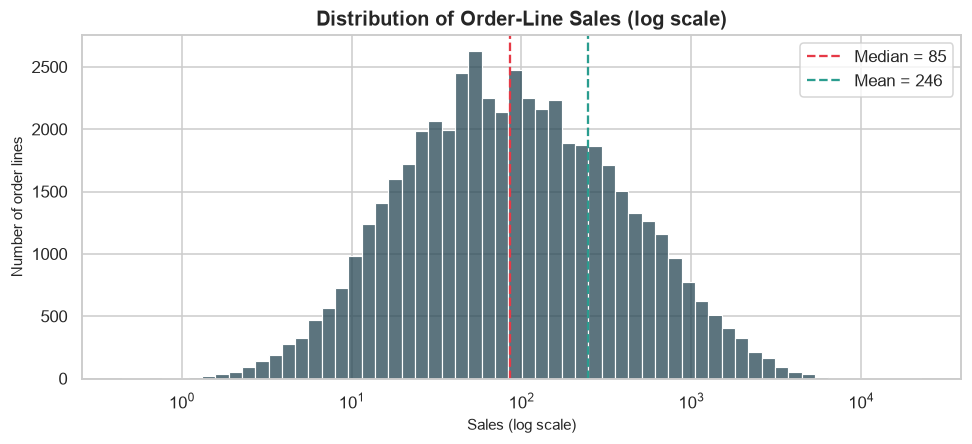

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(df.Sales, bins=60, log_scale=True, color=BLUE, ax=ax)
ax.axvline(df.Sales.median(), color=BAD, ls="--", label=f"Median = {df.Sales.median():,.0f}")
ax.axvline(df.Sales.mean(), color=GOOD, ls="--", label=f"Mean = {df.Sales.mean():,.0f}")
ax.set(title="Distribution of Order-Line Sales (log scale)", xlabel="Sales (log scale)", ylabel="Number of order lines"); ax.legend()
save("13_sales_distribution")

### Chart 14 – Distribution of Net Profit per Order Line

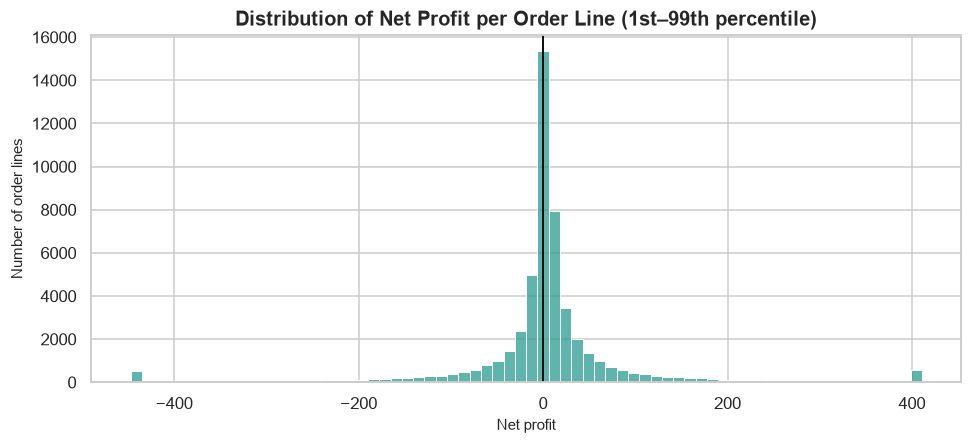

Loss-making lines: 21,150 (41.2%)


In [19]:
lo, hi = df.Net_Profit.quantile([.01, .99])
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(df.Net_Profit.clip(lo, hi), bins=70, color=GOOD, ax=ax)
ax.axvline(0, color="black", lw=1.2)
ax.set(title="Distribution of Net Profit per Order Line (1st–99th percentile)", xlabel="Net profit", ylabel="Number of order lines")
save("14_net_profit_distribution")
print(f"Loss-making lines: {(df.Net_Profit < 0).sum():,} ({(df.Net_Profit < 0).mean()*100:.1f}%)")

## 8. Relationships Between Variables

### Chart 15 – Correlation Heatmap

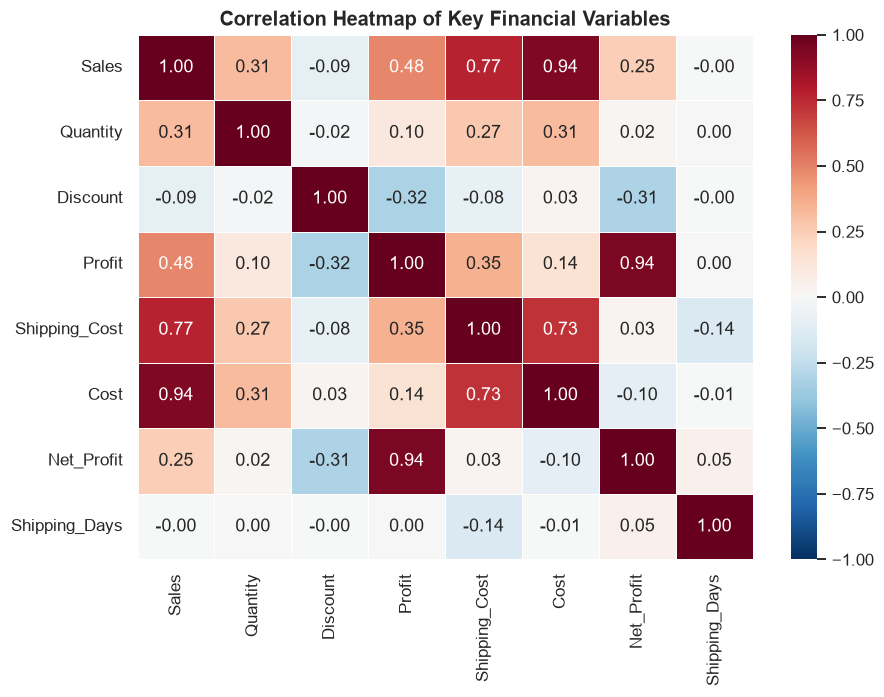

Discount vs Profit : -0.316
Sales vs Shipping  : 0.768
Sales vs Profit    : 0.485


In [20]:
cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping_Cost", "Cost", "Net_Profit", "Shipping_Days"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, ax=ax)
ax.set_title("Correlation Heatmap of Key Financial Variables")
save("15_correlation_heatmap")
print("Discount vs Profit :", round(corr.loc["Discount", "Profit"], 3))
print("Sales vs Shipping  :", round(corr.loc["Sales", "Shipping_Cost"], 3))
print("Sales vs Profit    :", round(corr.loc["Sales", "Profit"], 3))

## 9. Chart Inventory

In [21]:
files = sorted(p.name for p in VIS.glob("*.png"))
print(len(files), "charts saved in", VIS)
for f in files: print(" ", f)

15 charts saved in C:\Users\tanis\OneDrive\Desktop\cs-vision-internship\visualizations
  01_monthly_sales_trend.png
  02_monthly_net_profit.png
  03_yearly_sales_profit.png
  04_seasonality.png
  05_sales_by_category.png
  06_category_profit_margin.png
  07_subcategory_net_profit.png
  08_region_sales_vs_profit.png
  09_region_net_margin.png
  10_segment_performance.png
  11_discount_vs_profit.png
  12_shipping_cost_by_mode.png
  13_sales_distribution.png
  14_net_profit_distribution.png
  15_correlation_heatmap.png


## 10. Key Findings and Recommendations

**Findings (each is supported by the chart number shown)**
1. **Sales growth (Chart 3):** sales rose every year, from 2.26M (2011) to 4.30M (2014): +18.5%, +27.2% and +26.3% year on year.
2. **Seasonality (Charts 1, 4):** December, November and September are the strongest months; February, January and April are the weakest. Peak month: November 2014 (555K).
3. **Thin margins (Charts 2, 3):** gross margin is 11.6%, but shipping costs take 10.7% of sales, leaving a net margin of only 0.91%. 15 of 48 months had a net loss.
4. **Discounts destroy profit (Chart 11):** undiscounted lines earn +35 per line; lines discounted above 20% lose 64 to 109 per line. They are 22.1% of all lines and lose 1.02M in total.
5. **Furniture is loss-making (Charts 6, 7):** net profit −155K (−3.8% margin), driven by Tables (−144K, −19%). Technology is the best category (157K, 3.3%); Copiers is the best sub-category (99K).
6. **Three regions lose money (Charts 8, 9):** Southeast Asia (−75.8K, −8.6%), EMEA (−44.5K, −5.5%) and South (−28.1K, −1.8%). North Asia, North and Central Asia have the best margins; Canada has the highest margin (15.6%) but is small.
7. **Largest region earns little (Chart 8):** Central has 22% of sales but only a 0.5% net margin.
8. **Premium shipping is expensive (Chart 12):** Same Day and First Class cost 17.4% and 16.8% of sales, against 8.1% for Standard Class.
9. **Skewed sales (Charts 13, 14):** median order-line sales are 85 against a mean of 246; the top 10% of lines give 53.6% of sales, and 41.2% of lines lose money after shipping.
10. **Relationships (Chart 15):** discount and profit are negatively correlated (−0.32); sales and shipping cost are strongly correlated (0.77). Customer segments have similar margins (Home Office 1.4%, Consumer and Corporate 0.8%).

**Recommendations**
- Cap discounts at about 20% and require approval above that level.
- Review pricing and discounts on Tables, Chairs, Storage and Machines.
- Review shipping costs and pricing in Southeast Asia, EMEA and South.
- Encourage Standard Class shipping and charge a premium for Same Day and First Class.
- Prepare stock and marketing ahead of the September–December peak.